In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pymongo import MongoClient
from getpass import getpass
from urllib.parse import quote_plus

# Atlas에서 복사한 연결 문자열
uri_template = """
mongodb+srv://<db_username>:<db_password>@<cluster-host>/?retryWrites=true&w=majority
""".strip()

username = input("MongoDB 사용자 이름: ")
password = getpass("MongoDB 비밀번호: ")

uri = (
    uri_template
    .replace("<db_username>", quote_plus(username))
    .replace("<db_password>", quote_plus(password))
)

client = MongoClient(uri)

# MongoDB에서 메인 49개 데이터 조회
db = client["child_traffic_safety"]
collection = db["final_main_49"]

data = list(collection.find({}, {"_id": 0}))

df = pd.DataFrame(data)

print("MongoDB에서 불러온 지역 수:", len(df))
print("결측치 총합:", df.isna().sum().sum())

display(df.head())


In [16]:
# 2020~2025 누적 어린이사고를
# 2025년 어린이 인구 1만 명당 값으로 환산
df["accident_per_10k_child"] = (
    df["child_accident_count"]
    / df["child_population_0_12"]
    * 10000
)

# 어린이 인구 1,000명당 교통안전시설 수
df["crosswalk_per_1000_child"] = (
    df["crosswalk_count"]
    / df["child_population_0_12"]
    * 1000
)

df["traffic_light_per_1000_child"] = (
    df["traffic_light_count"]
    / df["child_population_0_12"]
    * 1000
)

df["schoolzone_per_1000_child"] = (
    df["schoolzone_count"]
    / df["child_population_0_12"]
    * 1000
)

print("파생변수 생성 완료")

display(
    df[
        [
            "SIDO_NM",
            "SIGUNGU_NM",
            "child_accident_count",
            "child_population_0_12",
            "accident_per_10k_child",
            "crosswalk_per_1000_child",
            "traffic_light_per_1000_child",
            "schoolzone_per_1000_child",
            "cctv_install_rate"
        ]
    ].head()
)

파생변수 생성 완료


,SIDO_NM,SIGUNGU_NM,child_accident_count,child_population_0_12,accident_per_10k_child,crosswalk_per_1000_child,traffic_light_per_1000_child,schoolzone_per_1000_child,cctv_install_rate
0,강원특별자치도,동해시,85,6852,124.051372,161.266783,168.417980,4.232341,0.689655
1,강원특별자치도,정선군,44,1570,280.254777,27.388535,10.191083,11.464968,0.888889
2,강원특별자치도,태백시,67,2273,294.764628,1.759789,23.757149,5.719314,1.000000
3,경기도,광명시,259,25790,100.426522,9.693680,11.516092,1.589763,0.560976
4,경기도,구리시,207,14765,140.196410,33.322045,225.194717,1.354555,0.950000


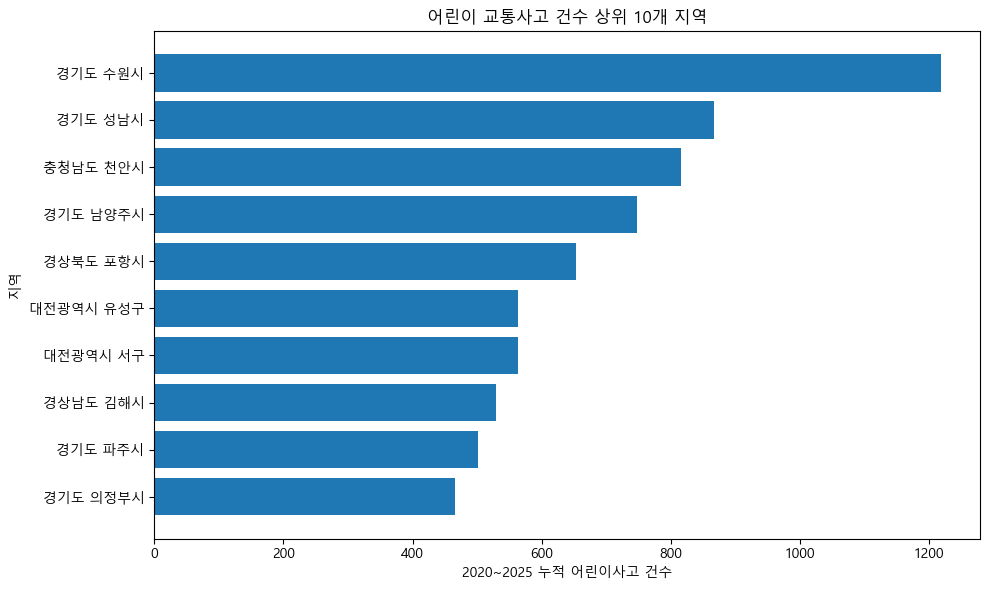

In [17]:
# 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 지역명 표시용
df["region_name"] = df["SIDO_NM"] + " " + df["SIGUNGU_NM"]

# 2020~2025 누적 어린이사고 건수 상위 10개 지역
top_accident = (
    df.sort_values("child_accident_count", ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_accident["region_name"],
    top_accident["child_accident_count"]
)

plt.xlabel("2020~2025 누적 어린이사고 건수")
plt.ylabel("지역")
plt.title("어린이 교통사고 건수 상위 10개 지역")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

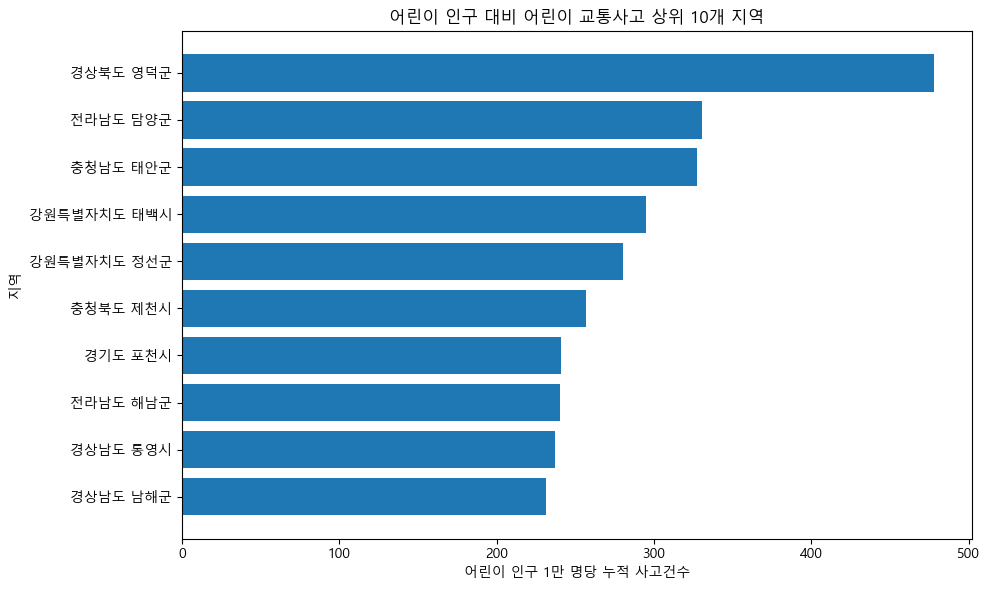

In [18]:
# 2025년 어린이 인구 1만 명당
# 2020~2025 누적 어린이사고 비율 상위 10개 지역
top_accident_rate = (
    df.sort_values("accident_per_10k_child", ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_accident_rate["region_name"],
    top_accident_rate["accident_per_10k_child"]
)

plt.xlabel("어린이 인구 1만 명당 누적 사고건수")
plt.ylabel("지역")
plt.title("어린이 인구 대비 어린이 교통사고 상위 10개 지역")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [19]:
# 사고 비율과 교통안전시설 지표의 Spearman 상관관계

analysis_cols = [
    "accident_per_10k_child",
    "crosswalk_per_1000_child",
    "traffic_light_per_1000_child",
    "schoolzone_per_1000_child",
    "cctv_install_rate"
]

corr = df[analysis_cols].corr(method="spearman")

accident_corr = (
    corr["accident_per_10k_child"]
    .drop("accident_per_10k_child")
    .sort_values()
)

print("어린이 인구 대비 누적 사고와의 Spearman 상관계수")
display(accident_corr.to_frame("spearman_corr"))

어린이 인구 대비 누적 사고와의 Spearman 상관계수


,spearman_corr
crosswalk_per_1000_child,0.019592
traffic_light_per_1000_child,0.133265
cctv_install_rate,0.312455
schoolzone_per_1000_child,0.695816


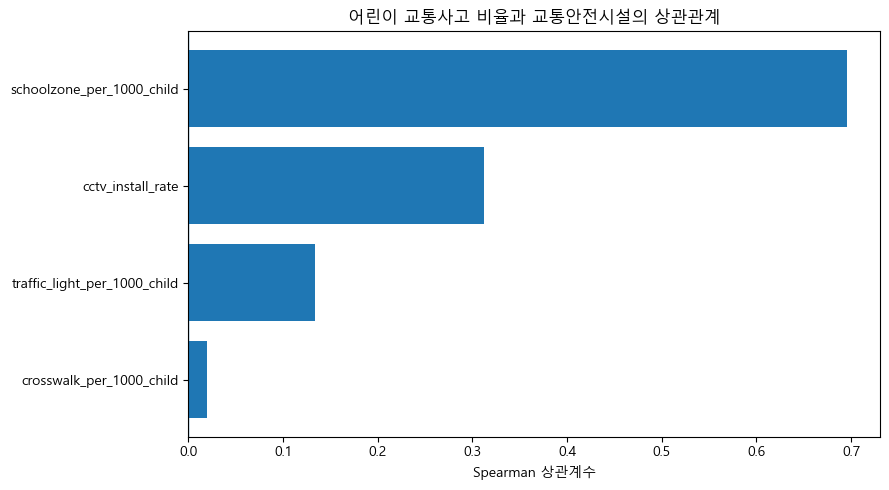

In [20]:
plt.figure(figsize=(9, 5))

plt.barh(
    accident_corr.index,
    accident_corr.values
)

plt.axvline(0, linewidth=1)

plt.xlabel("Spearman 상관계수")
plt.title("어린이 교통사고 비율과 교통안전시설의 상관관계")

plt.tight_layout()
plt.show()

In [21]:
from scipy.stats import spearmanr

facility_cols = [
    "crosswalk_per_1000_child",
    "traffic_light_per_1000_child",
    "schoolzone_per_1000_child",
    "cctv_install_rate"
]

results = []

for col in facility_cols:
    rho, p = spearmanr(
        df["accident_per_10k_child"],
        df[col]
    )

    results.append({
        "variable": col,
        "spearman_corr": rho,
        "p_value": p
    })

corr_result = pd.DataFrame(results)

display(corr_result)

,variable,spearman_corr,p_value
0,crosswalk_per_1000_child,0.019592,8.937068e-01
1,traffic_light_per_1000_child,0.133265,3.613183e-01
2,schoolzone_per_1000_child,0.695816,2.858815e-08
3,cctv_install_rate,0.312455,2.883228e-02


In [22]:
raw_cols = [
    "child_accident_count",
    "child_population_0_12",
    "crosswalk_count",
    "traffic_light_count",
    "schoolzone_count",
    "cctv_installed_zone_count"
]

raw_corr = df[raw_cols].corr(method="spearman")

display(
    raw_corr["child_accident_count"]
    .drop("child_accident_count")
    .sort_values(ascending=False)
    .to_frame("spearman_corr")
)

,spearman_corr
child_population_0_12,0.974029
cctv_installed_zone_count,0.877781
schoolzone_count,0.874541
crosswalk_count,0.664932
traffic_light_count,0.601475


In [23]:
check_cols = [
    "child_population_0_12",
    "accident_per_10k_child",
    "crosswalk_per_1000_child",
    "traffic_light_per_1000_child",
    "schoolzone_per_1000_child",
    "cctv_install_rate"
]

display(
    df[check_cols]
    .corr(method="spearman")["child_population_0_12"]
    .drop("child_population_0_12")
    .sort_values()
    .to_frame("어린이인구와의_상관계수")
)

,어린이인구와의_상관계수
schoolzone_per_1000_child,-0.760102
accident_per_10k_child,-0.666837
cctv_install_rate,-0.412880
crosswalk_per_1000_child,-0.164898
traffic_light_per_1000_child,-0.150204


In [25]:
from scipy.stats import rankdata, pearsonr
import numpy as np
import pandas as pd

def partial_spearman(x, y, control):
    # Spearman = 순위값으로 바꾼 뒤 Pearson 계산
    x_rank = rankdata(x)
    y_rank = rankdata(y)
    z_rank = rankdata(control)

    # 어린이 인구의 영향을 제거한 잔차 계산
    x_fit = np.polyval(np.polyfit(z_rank, x_rank, 1), z_rank)
    y_fit = np.polyval(np.polyfit(z_rank, y_rank, 1), z_rank)

    x_resid = x_rank - x_fit
    y_resid = y_rank - y_fit

    r, p = pearsonr(x_resid, y_resid)

    return r, p


facility_cols = [
    "crosswalk_per_1000_child",
    "traffic_light_per_1000_child",
    "schoolzone_per_1000_child",
    "cctv_install_rate"
]

results = []

for col in facility_cols:
    r, p = partial_spearman(
        df["accident_per_10k_child"],
        df[col],
        df["child_population_0_12"]
    )

    results.append({
        "시설": col,
        "부분상관계수": r,
        "p_value": p
    })

partial_result = pd.DataFrame(results)

display(partial_result)

,시설,부분상관계수,p_value
0,crosswalk_per_1000_child,-0.122949,0.399996
1,traffic_light_per_1000_child,0.044932,0.759178
2,schoolzone_per_1000_child,0.390207,0.005576
3,cctv_install_rate,0.054708,0.708886


In [26]:
# 각 지표를 0~1 사이의 순위점수로 변환
df["crosswalk_score"] = df["crosswalk_per_1000_child"].rank(pct=True)
df["traffic_light_score"] = df["traffic_light_per_1000_child"].rank(pct=True)
df["schoolzone_score"] = df["schoolzone_per_1000_child"].rank(pct=True)
df["cctv_score"] = df["cctv_install_rate"].rank(pct=True)

# 4개 시설지표 평균 = 종합 안전시설 수준
df["infrastructure_score"] = (
    df[
        [
            "crosswalk_score",
            "traffic_light_score",
            "schoolzone_score",
            "cctv_score"
        ]
    ].mean(axis=1)
)

# 사고 비율도 순위점수로 변환
df["risk_score"] = (
    df["accident_per_10k_child"]
    .rank(pct=True)
)

# 사고위험은 높은데 시설수준은 낮을수록 값이 커짐
df["priority_score"] = (
    df["risk_score"]
    - df["infrastructure_score"]
)

print("점수 생성 완료")

점수 생성 완료


In [27]:
priority_top10 = (
    df.sort_values(
        "priority_score",
        ascending=False
    )
    [
        [
            "SIDO_NM",
            "SIGUNGU_NM",
            "accident_per_10k_child",
            "risk_score",
            "infrastructure_score",
            "priority_score"
        ]
    ]
    .head(10)
)

display(priority_top10)

,SIDO_NM,SIGUNGU_NM,accident_per_10k_child,risk_score,infrastructure_score,priority_score
1,강원특별자치도,정선군,280.254777,0.918367,0.428571,0.489796
47,충청남도,태안군,327.309922,0.959184,0.484694,0.474490
27,경상북도,영덕군,478.142077,1.000000,0.540816,0.459184
2,강원특별자치도,태백시,294.764628,0.938776,0.489796,0.448980
37,전라남도,담양군,330.441966,0.979592,0.571429,0.408163
23,경상남도,통영시,236.984283,0.836735,0.438776,0.397959
48,충청북도,제천시,256.640143,0.897959,0.525510,0.372449
26,경상북도,상주시,220.332431,0.775510,0.469388,0.306122
40,전라남도,해남군,240.452617,0.857143,0.581633,0.275510
39,전라남도,여수시,190.003744,0.714286,0.469388,0.244898


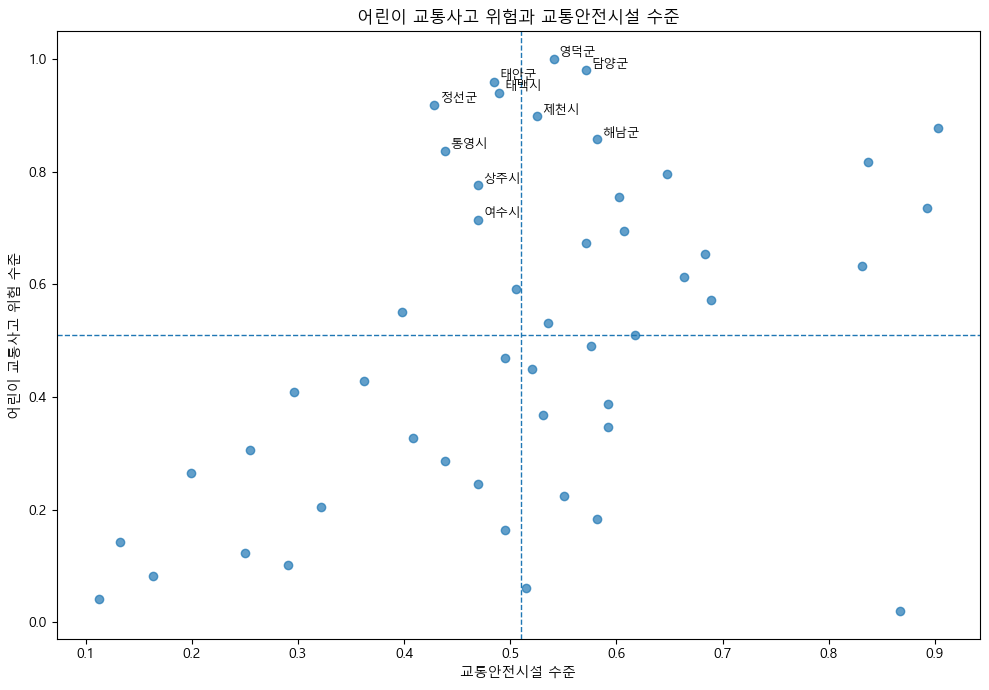

In [28]:
plt.figure(figsize=(10, 7))

plt.scatter(
    df["infrastructure_score"],
    df["risk_score"],
    alpha=0.7
)

# 평균선
plt.axvline(
    df["infrastructure_score"].mean(),
    linestyle="--",
    linewidth=1
)

plt.axhline(
    df["risk_score"].mean(),
    linestyle="--",
    linewidth=1
)

# 우선순위 상위 10개 지역 이름 표시
top10_idx = (
    df.nlargest(10, "priority_score").index
)

for idx in top10_idx:
    plt.text(
        df.loc[idx, "infrastructure_score"] + 0.005,
        df.loc[idx, "risk_score"] + 0.005,
        df.loc[idx, "SIGUNGU_NM"],
        fontsize=9
    )

plt.xlabel("교통안전시설 수준")
plt.ylabel("어린이 교통사고 위험 수준")
plt.title("어린이 교통사고 위험과 교통안전시설 수준")

plt.tight_layout()
plt.show()

In [29]:
df.to_csv(
    "../data_processed/eda_main_49.csv",
    index=False,
    encoding="utf-8-sig"
)

print("EDA 데이터 저장 완료")
print("지역 수:", len(df))

EDA 데이터 저장 완료
지역 수: 49


In [30]:
eda_collection = db["eda_main_49"]

eda_collection.delete_many({})

eda_records = df.to_dict("records")
eda_collection.insert_many(eda_records)

print(
    "MongoDB EDA 데이터:",
    eda_collection.count_documents({})
)

MongoDB EDA 데이터: 49
